# 🧪 LAB: Manual MLPs for Classification and Regression

In this lab, you will use `PyTorch` to implement manually a multi-layer perceptron (MLP) for three different tasks: binary classification, multi-class classification and regression.

## General instructions to complete in ALL three tasks:

1. ***IMPLEMENTATION***:
   
Implement a separate class for each task:

  - `BinaryMLP` for the binary classification task  
  - `MultiClassMLP` for the multi-class classification task  
  - `RegressionMLP` for the regression task

   Each class must include the following methods:

  - `__init__` for initializing 1 or 2 hidden layers. (*Help*: having a second hidden layer only means the need of having a extra set of weights and intercept).
  - `forward` to transfer information from the input to the output layer. (*Help*: make sure that information passes through a second hidden layer if there is one).
  - `cost` computing the cost.
  - `fit` for training, using the gradients to manually update the parameters of the model. **Use stochastic gradient descent to update your weights**. *N.B.* You may probably reuse much of the code we used in this week tutorial already.
  - `predict` to convert the information at the output layer into the required output.

2. ***DATA PREPARATION***

For each task, you will be provided with a toy dataset. For each dataset:

  - Split into training and holdout sets (use an 80/20 split)
  - Standardize the features properly, avoiding data leakage
  - Convert all data into `PyTorch` Tensors for compatibility

3. ***MODEL TRAINING AND EVALUATION***

Instantiate the model for each task and train it under different hyperparameter configurations. In each case, record the performance on **both** the training and holdout sets using the appropriate metric for the task (accuracy, MSE, etc.). You should explore the following configurations:

  - One hidden layer, varying the number of hidden units (use ReLU as their activation function)
  - Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
  - Repeat the above setups using Tanh activation instead of ReLU

Present your results in a compact way (e.g., a summary table, a data frame etc).

**NOTE**: When training your model, use a fixed learning rate of your choice (e.g., 0.01 is a reasonable starting point) and a reasonably large number of  epochs (e.g., 100–200) based on how training and holdout performance evolve.

4. ***REFLECTION AND DISCUSSION***

Reflect on the impact of the different hyperparameter settings:

- How does the number of hidden units affect performance?
- What changes when using two layers instead of one?
- How does the activation function (ReLU vs. Tanh) influence results?

Please elaborate your answers.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

**Ideally, each group member should be responsible for one of the separate tasks.** BUT, everyone should help each other along the way, both reviewing and refining results and discussion.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [3]:
NAMES = "Josh Ryan Adalia"

## 1. Pre-implementation Group Discussion (15 points)

Discuss and agree on:

- What cost function should be used for each of the below task.
- What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.
- Why it is important to standardize the data before training each model.
- How you could detect overfitting when training your models.

**What cost function should be used for each of the tasks below?**
For binary classification, we use binary cross-entropy. For multi-class classification, we use categorical cross-entropy. For regression, we use mean squared error (MSE) or root mean squared error (RMSE).

**What changes are needed in the output layer for each of these tasks? In particular, consider the number of units and the activation function.**
- **Binary classification:** The output layer has 1 unit with a sigmoid activation, which outputs a probability between 0 and 1 for the positive class.
- **Multi-class classification:** The output layer has N units, where N is the number of classes, with a softmax activation. Softmax produces a probability for each class, and the probabilities sum to 1.
- **Regression:** The output layer has 1 unit (or one per target value) with a linear activation, meaning no transformation is applied. This lets the model output any real number rather than a value restricted to a fixed range.

**Why is it important to standardize the data before training each model?**
Features measured on larger scales can dominate the weight updates during gradient descent, so the model effectively treats them as more important regardless of their actual predictive value. Standardizing each feature to a mean of 0 and a standard deviation of 1 puts all features on equal footing. It also helps gradient descent converge faster and more reliably.

**How could you detect overfitting when training your models?**
We can detect overfitting by comparing performance on the training set to performance on a held-out validation set. If the training loss keeps decreasing while the validation loss levels off or starts increasing, the model is memorizing the training data instead of learning patterns that generalize. Plotting the training and validation loss (or accuracy) curves over epochs makes this gap easy to spot. A large gap between training and validation accuracy at the end of training is another sign of overfitting.

## 2. Binary Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [4]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
import torch
import pandas as pd
import matplotlib.pyplot as plt

# Split first, then scale (fit the scaler on train only, to avoid data leakage)
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)
X_train, X_report, y_train, y_report = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_report = scaler.transform(X_report)

# Convert the data to PyTorch tensors (targets as (n, 1) columns to match forward())
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_report = torch.tensor(X_report, dtype=torch.float32)
y_report = torch.tensor(y_report, dtype=torch.float32).view(-1, 1)

In [ ]:
class BinaryMLP:
    def __init__(self, input_dim, hidden_dim, n_hidden=1, activation_fn=torch.relu, lr=0.01, seed=42):
        # Only 1 or 2 hidden layers are allowed
        if n_hidden not in (1, 2):
            raise ValueError("n_hidden must be 1 or 2")
        torch.manual_seed(seed)
        self.n_hidden = n_hidden
        self.lr = lr
        self.activation_fn = activation_fn

        # Hidden layer 1: input_dim -> hidden_dim
        # requires_grad=True tells PyTorch to track gradients for these tensors
        self.w1 = torch.randn(input_dim, hidden_dim, requires_grad=True)
        self.b1 = torch.randn(hidden_dim, requires_grad=True)

        # Hidden layer 2 (optional): hidden_dim -> hidden_dim (same width)
        if n_hidden == 2:
            self.w2 = torch.randn(hidden_dim, hidden_dim, requires_grad=True)
            self.b2 = torch.randn(hidden_dim, requires_grad=True)

        # Output layer: hidden_dim -> 1 unit (one probability for binary)
        self.w_out = torch.randn(hidden_dim, 1, requires_grad=True)
        self.b_out = torch.randn(1, requires_grad=True)

        # Keep every parameter in a list so fit() can update them in one loop
        self.params = [self.w1, self.b1]
        if n_hidden == 2:
            self.params += [self.w2, self.b2]
        self.params += [self.w_out, self.b_out]

    def forward(self, X):
        # Hidden layer 1: linear step, then activation function
        h = self.activation_fn(X @ self.w1 + self.b1)
        # Hidden layer 2 only runs if it exists
        if self.n_hidden == 2:
            h = self.activation_fn(h @ self.w2 + self.b2)
        # Output: sigmoid squashes the value into (0, 1), giving a probability
        return torch.sigmoid(h @ self.w_out + self.b_out)

    def cost(self, y_hat, y):
        # Binary cross-entropy. clamp avoids log(0) = -inf
        y_hat = y_hat.clamp(1e-7, 1 - 1e-7)
        return -(y * torch.log(y_hat) + (1 - y) * torch.log(1 - y_hat)).mean()

    def fit(self, X, y, epochs=50, X_val=None, y_val=None):
        self.train_losses, self.val_losses = [], []
        n = X.shape[0]
        for epoch in range(epochs):
            # Shuffle the training data
            for i in torch.randperm(n):
                loss = self.cost(self.forward(X[i:i+1]), y[i:i+1])
                loss.backward()                  # autograd computes the gradients
                with torch.no_grad():            # don't track the update step itself
                    for p in self.params:
                        p -= self.lr * p.grad    # gradient-descent step
                        p.grad.zero_()           # reset, or gradients add up across steps

            # Record the losses on the full sets once per epoch (useful for spotting overfitting)
            with torch.no_grad():
                self.train_losses.append(self.cost(self.forward(X), y).item())
                if X_val is not None:
                    self.val_losses.append(self.cost(self.forward(X_val), y_val).item())
        return self

    def predict(self, X, threshold=0.5):
        # Turn probabilities into 0/1 class labels
        with torch.no_grad():
            return (self.forward(X) >= threshold).int()

In [6]:
LR = 0.01
EPOCHS = 200

# Hyperparameter grid:
hidden_sizes = [2, 4, 8, 16, 32]
activations = {"ReLU": torch.relu, "Tanh": torch.tanh}

results = []   # one dict (row) per configuration
models = {}    # keep trained models so we can look at their loss curves later

for act_name, act_fn in activations.items():
    for n_hidden in (1, 2):
        for h in hidden_sizes:
            # Same seed for every model -> differences come from the hyperparameters, not the random start
            model = BinaryMLP(input_dim=2, hidden_dim=h, n_hidden=n_hidden, activation_fn=act_fn, lr=LR, seed=42)
            model.fit(X_train, y_train, epochs=EPOCHS, X_val=X_report, y_val=y_report)
            models[(act_name, n_hidden, h)] = model

            # Accuracy on BOTH sets: a big train-holdout gap would signal overfitting
            results.append({
                "activation": act_name,
                "hidden_layers": n_hidden,
                "hidden_units": h,
                "train_acc": accuracy_score(y_train, model.predict(X_train)),
                "holdout_acc": accuracy_score(y_report, model.predict(X_report)),
            })
            print(f"done: {act_name}, {n_hidden} layer(s), {h} units")  # progress, since this takes a while

results_df = pd.DataFrame(results)

# Compact summary table:
#   rows    = activation x hidden units
#   columns = metric x number of hidden layers (so 1 vs 2 layers sit side by side)
# pivot_table reshapes the long list of rows into this grid
summary = results_df.pivot_table(index=["activation", "hidden_units"], columns="hidden_layers", values=["train_acc", "holdout_acc"]).round(3)
summary

done: ReLU, 1 layer(s), 2 units
done: ReLU, 1 layer(s), 4 units
done: ReLU, 1 layer(s), 8 units
done: ReLU, 1 layer(s), 16 units
done: ReLU, 1 layer(s), 32 units
done: ReLU, 2 layer(s), 2 units
done: ReLU, 2 layer(s), 4 units
done: ReLU, 2 layer(s), 8 units
done: ReLU, 2 layer(s), 16 units
done: ReLU, 2 layer(s), 32 units
done: Tanh, 1 layer(s), 2 units
done: Tanh, 1 layer(s), 4 units
done: Tanh, 1 layer(s), 8 units
done: Tanh, 1 layer(s), 16 units
done: Tanh, 1 layer(s), 32 units
done: Tanh, 2 layer(s), 2 units
done: Tanh, 2 layer(s), 4 units
done: Tanh, 2 layer(s), 8 units
done: Tanh, 2 layer(s), 16 units
done: Tanh, 2 layer(s), 32 units


holdout_acc        train_acc       
hidden_layers                     1      2         1      2
activation hidden_units                                    
ReLU       2                  0.850  0.855     0.869  0.870
           4                  0.875  0.990     0.876  0.972
           8                  0.980  0.980     0.971  0.978
           16                 0.985  0.975     0.978  0.978
           32                 0.980  0.985     0.978  0.980
Tanh       2                  0.855  0.860     0.869  0.868
           4                  0.965  0.985     0.972  0.978
           8                  0.990  0.970     0.972  0.979
           16                 0.980  0.975     0.981  0.982
           32                 0.990  0.975     0.979  0.981

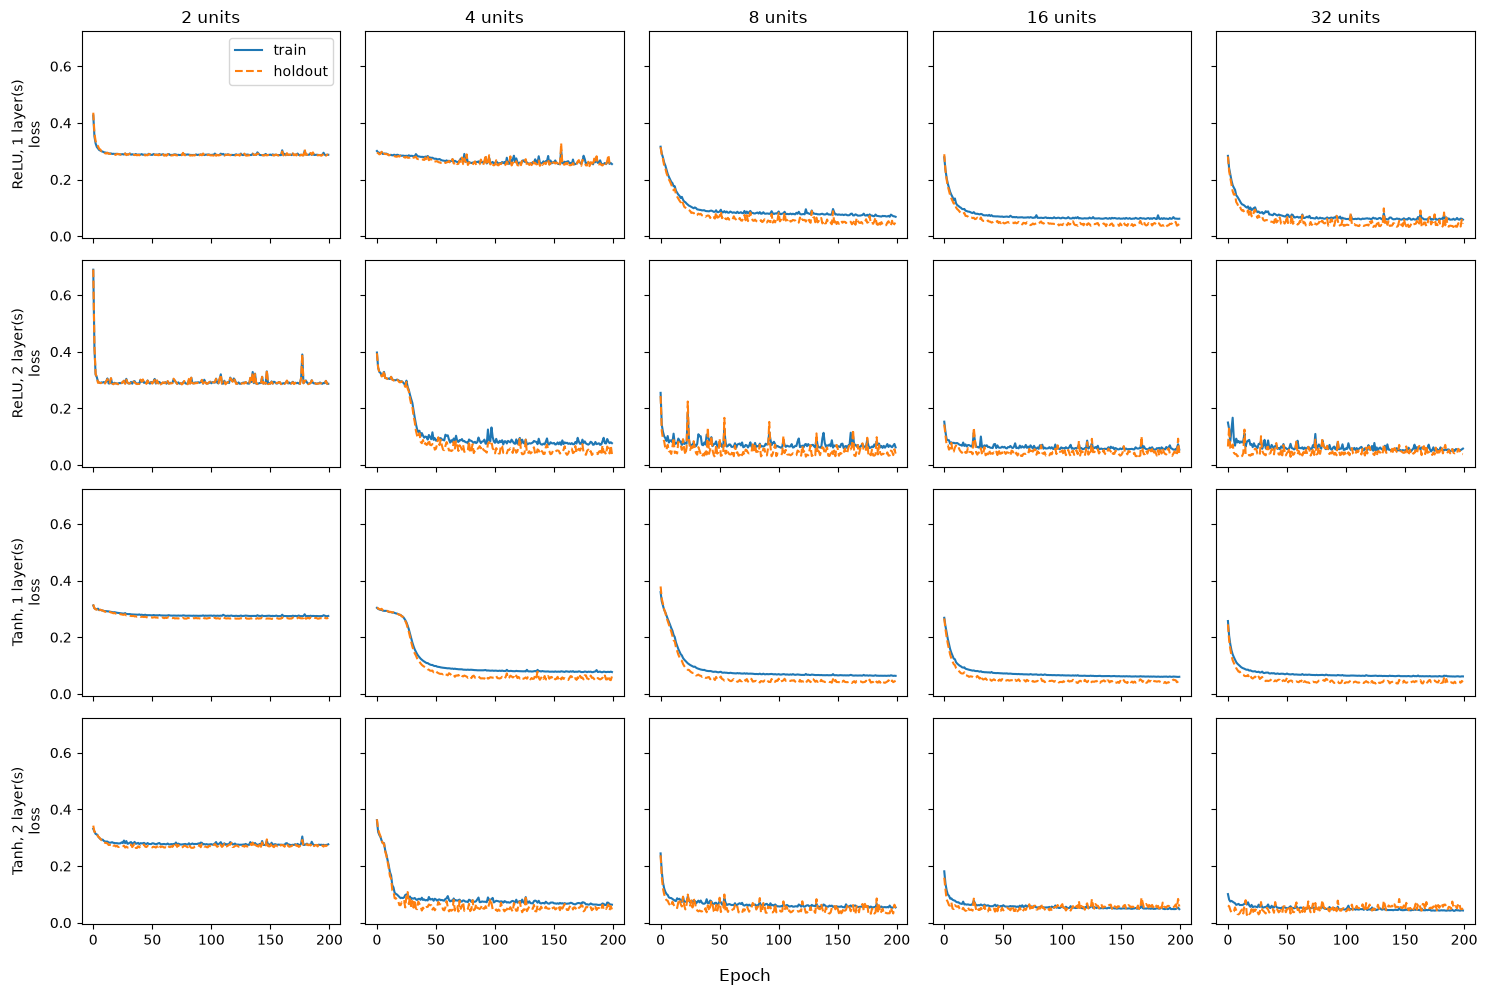

In [7]:
# Grid: rows = (activation, n_layers) combos, columns = hidden sizes
combos = [(a, n) for a in activations for n in (1, 2)]
fig, axes = plt.subplots(len(combos), len(hidden_sizes),
                         figsize=(3 * len(hidden_sizes), 2.5 * len(combos)),
                         sharex=True, sharey=True)   # shared axes make panels comparable

for r, (act, n) in enumerate(combos):
    for c, h in enumerate(hidden_sizes):
        m, ax = models[(act, n, h)], axes[r, c]
        ax.plot(m.train_losses, label="train")
        ax.plot(m.val_losses, label="holdout", linestyle="--")
        if r == 0:
            ax.set_title(f"{h} units")
        if c == 0:
            ax.set_ylabel(f"{act}, {n} layer(s)\nloss")

axes[0, 0].legend()
fig.supxlabel("Epoch")
plt.tight_layout()
plt.show()

4. ***REFLECTION AND DISCUSSION***

**How does the number of hidden units affect performance?**

The number of hidden units had the largest effect on performance, especially at the low end. With only 2 hidden units, every configuration underfit: holdout accuracy stayed around 0.85–0.86, training accuracy was nearly identical (~0.87), and the loss curves flattened out early at about 0.28–0.29. Because training and holdout performance were both low and close together, the problem was too little model capacity rather than overfitting. With 2 units the network is too small to represent the decision boundary. Increasing to 4 units helped in most cases, and from 8 units onward every configuration reached roughly 0.97–0.99 holdout accuracy with loss settling near 0.05. Beyond 8 units the gains were minimal; 16 and 32 units performed about the same as 8. The small differences between these larger models (e.g., 0.975 vs. 0.985) amount to only one or two holdout examples and are likely noise rather than meaningful improvements. Even at 32 units we saw no overwhelming signs of clear overfitting. The holdout loss stayed at or slightly below the training loss throughout training.

**What changes when using two layers instead of one?**

A second hidden layer helped most when each layer was small. The clearest example is ReLU with 4 units, where holdout accuracy jumped from 0.875 with one layer to 0.99 with two. The one-layer version stayed stuck near a loss of 0.27, while the two-layer version plateaued for about 25 epochs and then dropped sharply to around 0.07. Tanh with 4 units also improved, from 0.965 to 0.985. The added depth lets the network combine features from the first layer into more complex ones, making up for the limited width. The extra layer did not help in every case. With 2 units per layer, two layers performed no better than one, because the 2-unit bottleneck still limits how much information passes through. At 8 units and above, two layers gave no consistent improvement and were sometimes slightly worse (e.g., ReLU 16 units: 0.985 -> 0.975; Tanh 8 units: 0.99 -> 0.97). Two-layer models generally converged in fewer epochs, but their loss curves were noisier, with more frequent spikes. Once the network has enough capacity, adding depth makes training less stable without improving accuracy.

**How does the activation function (ReLU vs. Tanh) influence results?**

The activation function mattered mostly for small networks. With one hidden layer of 4 units, Tanh reached 0.965 holdout accuracy compared with 0.875 for ReLU. Tanh is smooth and produces nonzero gradients for all inputs, so every unit continues to contribute. Tanh also produced smoother, more stable loss curves, while the ReLU curves (especially with two layers) showed more spikes during training. Once the networks had 8 or more units, both activation functions reached similar accuracy (about 0.98–0.99), so the choice of activation had little effect at that size.

**Summary**

Model capacity was the main factor in performance. Too few units caused underfitting, and roughly 8 units in a single layer was enough to reach about 0.98 holdout accuracy. A second layer and the Tanh activation both helped when the network was small but offered little benefit once it had enough units. None of the configurations showed clear signs of overfitting, so a small single-layer network with about 8 units would be a reasonable, efficient choice for this dataset.

## 2. Multi-Class Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

---
**NOTE**: This will likely be the most challenging exercise. To help you, here are some pointers:

 - The **output (last) layer** should have as many units as there are classes in your data.  

 - The **activation function of the output layer must be softmax**, not sigmoid. Softmax ensures that all output values are between 0 and 1 and sum to 1, so they can be interpreted as probabilities across the different classes. (*Help*: you may want to look into `torch.nn.functional` to find its implementation...)

 - For a multi-class problem, your target variable `y` should be **one-hot encoded**. For example:  
   - Label = 0 → [1, 0, 0]  
   - Label = 1 → [0, 1, 0]  
   - Label = 2 → [0, 0, 1]  
   You can easily achieve this with `OneHotEncoder` from `sklearn.preprocessing`.  

 - The **predicted class** corresponds to the unit with the highest probability.  
   Example:  
   - `[0.1, 0.3, 0.6] → class 2`  
   - `[0.6, 0.2, 0.2] → class 0`  

 - For this exercise, you need to **implement the categorical cross-entropy loss** (an extension of binary cross-entropy to multiple classes). It is defined as:  

   $$\sum_{c=1}^{l} y_{o,c}\,\log(p_{o,c}),$$

   where $l$ is the number of classes, $y_{o,c}$ is the one-hot encoded label for observation $o$, and $p_{o,c}$ is the predicted probability for class $c$ (after applying softmax). The log is the natural logarithm.

---

In [8]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_classes=3,
                           n_clusters_per_class=1,
                           n_features=2, n_informative=2, n_redundant=0, random_state=1234, flip_y=0.15)

In [9]:
# import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder
import torch
import torch.nn as nn

In [10]:
# 1. Implementation of One Hidden Layer
class MultiClassMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, n_classes, act_func=torch.relu, learning_rate=0.01):
        super().__init__()
        sizes = [input_dim] + hidden_dim + [n_classes]
        self.weights = nn.ParameterList()
        self.biases = nn.ParameterList()
        for i in range(len(sizes)-1):
            self.weights.append(nn.Parameter(torch.randn(sizes[i], sizes[i+1])))
            self.biases.append(nn.Parameter(torch.randn(1, sizes[i+1])))
        self.act_func = act_func
        self.hidden_dim = hidden_dim
        self.learning_rate = learning_rate
        self.train_history = {"cost": [], "acc": []}
        self.history = {"model": [], "train_cost": [], "train_acc": [], "test_cost": [], "test_acc": []}
        
    def forward(self, X):
        for i in range(len(self.weights)-1):
            linear = torch.matmul(X, self.weights[i]) + self.biases[i]
            X = self.act_func(linear)
        out = torch.matmul(X, self.weights[-1]) + self.biases[-1]
        return torch.softmax(out, dim=1)

    def cost(self, y_pred, y_true):
        cost = 0
        for ii in range(y_true.shape[1]):
            y_oc = y_true[:, ii]
            y_pc = y_pred[:, ii]
            cost -= y_oc*torch.log(y_pc.clamp_min(1e-12))
        return cost.mean(0)

    def fit(self, X, y, n_epochs=100):
        self.train()
        for epoch in range(n_epochs):
            randperm = torch.randperm(X.shape[0])
            for ii in randperm:
                x_batch, y_batch = X[ii:ii+1], y[ii:ii+1]
                probs = self.forward(x_batch)
                cost = self.cost(probs, y_batch)
                cost.backward()
                with torch.no_grad():
                    for p in self.parameters():
                        p -= self.learning_rate * p.grad
                        p.grad.zero_() 
            with torch.no_grad():
                final_epoch_cost = self.cost(self.forward(X), y).item()
                probs = self.forward(X)
                y_pred = probs.argmax(dim=1)
                acc = (y_pred == y.argmax(dim=1)).float().mean().item()
            self.train_history["cost"].append(final_epoch_cost)
            self.train_history["acc"].append(acc)
        self.eval()
        return self

    def predict(self, X):
        self.eval()
        with torch.no_grad():
            return self.forward(X).argmax(dim=1)

    def test_evaluation(self, X, y):
        with torch.no_grad():
            probs = self.forward(X)
            test_cost = self.cost(probs, y).item()
            y_pred = probs.argmax(dim=1)
            test_acc = (y_pred == y.argmax(dim=1)).float().mean().item()
        self.history["test_cost"].append(test_cost)
        self.history["test_acc"].append(test_acc)
        self.history["train_cost"].append(self.train_history["cost"][-1])
        self.history["train_acc"].append(self.train_history["acc"][-1])
        self.history["model"].append(f"{len(self.hidden_dim)} layer, {self.hidden_dim[0]} units, {self.act_func.__name__}")
        return pd.DataFrame(self.history)

In [11]:
# 2. Data Preparation

# One Hot Encode before split
y_re = y.reshape(-1,1)
onehot = OneHotEncoder(sparse_output=False)
y = onehot.fit_transform(y_re)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Numpy arrays to tensor for better flow
X_train = torch.tensor(X_train).float()
X_test = torch.tensor(X_test).float()
y_train = torch.tensor(y_train).float()
y_test = torch.tensor(y_test).float()

In [12]:
# 3. Model Training and Evaluation
# One hidden layer, varying the number of hidden units (use ReLU as their activation function)

torch.manual_seed(0)
# Create the model
multi_mlp_model_6 = MultiClassMLP(input_dim=X.shape[1], hidden_dim=[6], n_classes=3)
# Fit the model
multi_mlp_model_6.fit(X_train, y_train)

MultiClassMLP(
  (weights): ParameterList(
      (0): Parameter containing: [torch.float32 of size 2x6]
      (1): Parameter containing: [torch.float32 of size 6x3]
  )
  (biases): ParameterList(
      (0): Parameter containing: [torch.float32 of size 1x6]
      (1): Parameter containing: [torch.float32 of size 1x3]
  )
)

In [13]:
# 3. Model Training and Evaluation
# One hidden layer, varying the number of hidden units (use ReLU as their activation function)
torch.manual_seed(0)
# Create the model
multi_mlp_model_9 = MultiClassMLP(input_dim=X.shape[1], hidden_dim=[9], n_classes=3)
# Fit the model
multi_mlp_model_9.fit(X_train, y_train)

MultiClassMLP(
  (weights): ParameterList(
      (0): Parameter containing: [torch.float32 of size 2x9]
      (1): Parameter containing: [torch.float32 of size 9x3]
  )
  (biases): ParameterList(
      (0): Parameter containing: [torch.float32 of size 1x9]
      (1): Parameter containing: [torch.float32 of size 1x3]
  )
)

In [14]:
# 3. Model Training and Evaluation
# One hidden layer, varying the number of hidden units (use ReLU as their activation function)
torch.manual_seed(0)
# Create the model
multi_mlp_model_12 = MultiClassMLP(input_dim=X.shape[1], hidden_dim=[12], n_classes=3)
# Fit the model
multi_mlp_model_12.fit(X_train, y_train)

MultiClassMLP(
  (weights): ParameterList(
      (0): Parameter containing: [torch.float32 of size 2x12]
      (1): Parameter containing: [torch.float32 of size 12x3]
  )
  (biases): ParameterList(
      (0): Parameter containing: [torch.float32 of size 1x12]
      (1): Parameter containing: [torch.float32 of size 1x3]
  )
)

In [15]:
# 3. Model Training and Evaluation
# Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
torch.manual_seed(0)
# Create the model
multi_mlp_model_2hidden = MultiClassMLP(input_dim=X.shape[1], hidden_dim=[12,12], n_classes=3)
# Fit the model
multi_mlp_model_2hidden.fit(X_train, y_train)

MultiClassMLP(
  (weights): ParameterList(
      (0): Parameter containing: [torch.float32 of size 2x12]
      (1): Parameter containing: [torch.float32 of size 12x12]
      (2): Parameter containing: [torch.float32 of size 12x3]
  )
  (biases): ParameterList(
      (0): Parameter containing: [torch.float32 of size 1x12]
      (1): Parameter containing: [torch.float32 of size 1x12]
      (2): Parameter containing: [torch.float32 of size 1x3]
  )
)

In [16]:
# 3. Model Training and Evaluation
# Repeat ALL of the above setups using Tanh activation instead of ReLU
torch.manual_seed(0)
# Create the model
multi_mlp_model_tanh1 = MultiClassMLP(input_dim=X.shape[1], hidden_dim=[6], act_func=torch.tanh, n_classes=3)
# Fit the model
multi_mlp_model_tanh1.fit(X_train, y_train)

MultiClassMLP(
  (weights): ParameterList(
      (0): Parameter containing: [torch.float32 of size 2x6]
      (1): Parameter containing: [torch.float32 of size 6x3]
  )
  (biases): ParameterList(
      (0): Parameter containing: [torch.float32 of size 1x6]
      (1): Parameter containing: [torch.float32 of size 1x3]
  )
)

In [17]:
# 3. Model Training and Evaluation
# Repeat ALL of the above setups using Tanh activation instead of ReLU
torch.manual_seed(0)
# Create the model
multi_mlp_model_tanh2 = MultiClassMLP(input_dim=X.shape[1], hidden_dim=[9], act_func=torch.tanh, n_classes=3)
# Fit the model
multi_mlp_model_tanh2.fit(X_train, y_train)

MultiClassMLP(
  (weights): ParameterList(
      (0): Parameter containing: [torch.float32 of size 2x9]
      (1): Parameter containing: [torch.float32 of size 9x3]
  )
  (biases): ParameterList(
      (0): Parameter containing: [torch.float32 of size 1x9]
      (1): Parameter containing: [torch.float32 of size 1x3]
  )
)

In [18]:
# 3. Model Training and Evaluation
# One hidden layer, varying the number of hidden units (use ReLU as their activation function)
torch.manual_seed(0)
# Create the model
multi_mlp_model_tanh3 = MultiClassMLP(input_dim=X.shape[1], hidden_dim=[12], act_func=torch.tanh, n_classes=3)
# Fit the model
multi_mlp_model_tanh3.fit(X_train, y_train)

MultiClassMLP(
  (weights): ParameterList(
      (0): Parameter containing: [torch.float32 of size 2x12]
      (1): Parameter containing: [torch.float32 of size 12x3]
  )
  (biases): ParameterList(
      (0): Parameter containing: [torch.float32 of size 1x12]
      (1): Parameter containing: [torch.float32 of size 1x3]
  )
)

In [19]:
# 3. Model Training and Evaluation
# Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
torch.manual_seed(0)
# Create the model
multi_mlp_model_tanh4 = MultiClassMLP(input_dim=X.shape[1], hidden_dim=[12,12], act_func=torch.tanh, n_classes=3)
# Fit the model
multi_mlp_model_tanh4.fit(X_train, y_train)

MultiClassMLP(
  (weights): ParameterList(
      (0): Parameter containing: [torch.float32 of size 2x12]
      (1): Parameter containing: [torch.float32 of size 12x12]
      (2): Parameter containing: [torch.float32 of size 12x3]
  )
  (biases): ParameterList(
      (0): Parameter containing: [torch.float32 of size 1x12]
      (1): Parameter containing: [torch.float32 of size 1x12]
      (2): Parameter containing: [torch.float32 of size 1x3]
  )
)

In [20]:
df1 = multi_mlp_model_6.test_evaluation(X_test, y_test)
df2 = multi_mlp_model_9.test_evaluation(X_test, y_test)
df3 = multi_mlp_model_12.test_evaluation(X_test, y_test)
df4 = multi_mlp_model_2hidden.test_evaluation(X_test, y_test)
df5 = multi_mlp_model_tanh1.test_evaluation(X_test, y_test)
df6 = multi_mlp_model_tanh2.test_evaluation(X_test, y_test)
df7 = multi_mlp_model_tanh3.test_evaluation(X_test, y_test)
df8 = multi_mlp_model_tanh4.test_evaluation(X_test, y_test)

In [21]:
df_list = [df1,df2,df3,df4,df5,df6,df7,df8]
combined_results = pd.concat(df_list, axis=0, ignore_index=True)

In [22]:
combined_results

,model,train_cost,train_acc,test_cost,test_acc
0,"1 layer, 6 units, relu",0.553320,0.82125,0.621847,0.795
1,"1 layer, 9 units, relu",0.560691,0.80750,0.624367,0.795
2,"1 layer, 12 units, relu",0.550080,0.81375,0.598647,0.795
3,"2 layer, 12 units, relu",0.522317,0.82250,0.579273,0.815
4,"1 layer, 6 units, tanh",0.540266,0.82000,0.576760,0.800
5,"1 layer, 9 units, tanh",0.551444,0.80625,0.614633,0.790
6,"1 layer, 12 units, tanh",0.543770,0.81750,0.595210,0.800
7,"2 layer, 12 units, tanh",0.508893,0.82875,0.554782,0.815


### 4. Reflection

**How does the number of hidden units affect performance?**

The number of hidden units had almost no effect. With one ReLU layer, 6, 9 and 12 units all reached 0.795 holdout accuracy, and training accuracy stayed between 0.81 and 0.82. Tanh showed the same pattern, with holdout accuracy between 0.790 and 0.800. Even a small network is enough for this 2-feature problem, so adding units doesn't help. Training and holdout accuracy were within about 0.01–0.03 of each other, so no model clearly overfit.

**What changes when using two layers instead of one?**

Two layers of 12 units gave the best results, but the gain was small. Holdout accuracy rose from 0.795 to 0.815 with ReLU and from 0.800 to 0.815 with Tanh. Holdout cost also dropped (0.599 → 0.579 for ReLU, 0.595 → 0.555 for Tanh). The holdout set has 200 observations, so this gain is only about 4 more correct predictions.

**How does the activation function (ReLU vs. Tanh) influence results?**

Tanh usually had a slightly lower cost than ReLU, for example a holdout cost of 0.555 vs 0.579 with two layers. Holdout accuracy differed by at most 0.005, and with 9 units ReLU did slightly better (0.795 vs 0.790). The differences are about 0.01–0.02, so neither activation was clearly better for this dataset.

## 3: Regression Task (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [23]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, n_informative=2, random_state=1234, noise=75)

In [24]:
import torch
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(1234)
np.random.seed(1234)

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1234)

# Standardize features
x_scaler = StandardScaler().fit(X_train)
X_train_s = x_scaler.transform(X_train)
X_test_s = x_scaler.transform(X_test)

# Standardize target
y_scaler = StandardScaler().fit(y_train.reshape(-1, 1))
y_train_s = y_scaler.transform(y_train.reshape(-1, 1))
y_test_s = y_scaler.transform(y_test.reshape(-1, 1))

# Tensors
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train_s, dtype=torch.float32)
y_test_t = torch.tensor(y_test_s, dtype=torch.float32)

print("Train:", X_train_t.shape, y_train_t.shape)
print("Holdout:", X_test_t.shape, y_test_t.shape)

Train: torch.Size([800, 2]) torch.Size([800, 1])
Holdout: torch.Size([200, 2]) torch.Size([200, 1])


In [25]:
class RegressionMLP:
    def __init__(self, n_inputs, n_hidden, n_layers=1, activation="relu", seed=1234):
        assert n_layers in (1, 2), "Only 1 or 2 hidden layers are supported"
        torch.manual_seed(seed)
        self.n_layers = n_layers
        self.activation_name = activation
        self.act = torch.relu if activation == "relu" else torch.tanh

        # Scaled random init keeps early activations in a reasonable range
        def init(n_in, n_out):
            W = (torch.randn(n_in, n_out) * np.sqrt(2.0 / n_in)).requires_grad_()
            b = torch.zeros(n_out, requires_grad=True)
            return W, b

        # First hidden layer
        self.W1, self.b1 = init(n_inputs, n_hidden)
        # Second hidden layer
        if n_layers == 2:
            self.W2, self.b2 = init(n_hidden, n_hidden)
        # Output layer
        self.W_out, self.b_out = init(n_hidden, 1)

    def parameters(self):
        params = [self.W1, self.b1]
        if self.n_layers == 2:
            params += [self.W2, self.b2]
        params += [self.W_out, self.b_out]
        return params

    def forward(self, X):
        h = self.act(X @ self.W1 + self.b1)
        if self.n_layers == 2:
            h = self.act(h @ self.W2 + self.b2)
        # Identity activation at the output for regression
        return h @ self.W_out + self.b_out

    def cost(self, y_pred, y_true):
        # Mean squared error
        return torch.mean((y_pred - y_true) ** 2)

    def fit(self, X, y, lr=0.01, epochs=200, batch_size=32, X_val=None, y_val=None):
        self.history = {"train_cost": [], "val_cost": []}
        n = X.shape[0]
        for epoch in range(epochs):
            perm = torch.randperm(n)
            for i in range(0, n, batch_size):
                idx = perm[i:i + batch_size]
                loss = self.cost(self.forward(X[idx]), y[idx])
                loss.backward()
                with torch.no_grad():
                    for p in self.parameters():
                        p -= lr * p.grad
                        p.grad.zero_()
            # Track cost on full train
            with torch.no_grad():
                self.history["train_cost"].append(self.cost(self.forward(X), y).item())
                if X_val is not None:
                    self.history["val_cost"].append(self.cost(self.forward(X_val), y_val).item())
        return self

    def predict(self, X):
        # The output unit already is the predicted value
        with torch.no_grad():
            return self.forward(X)

In [31]:
from sklearn.metrics import mean_squared_error, r2_score

def evaluate(model, X_t, y_true_original):
    pred_s = model.predict(X_t).numpy()
    pred = y_scaler.inverse_transform(pred_s).ravel()
    return mean_squared_error(y_true_original, pred), r2_score(y_true_original, pred)

hidden_units = [2, 4, 8, 16, 32, 64]
results = []
models = {}

for activation in ["relu", "tanh"]:
    for n_layers in [1, 2]:
        for h in hidden_units:
            model = RegressionMLP(n_inputs=2, n_hidden=h, n_layers=n_layers, activation=activation)
            model.fit(X_train_t, y_train_t, lr=0.01, epochs=200, batch_size=1,
                      X_val=X_test_t, y_val=y_test_t)
            tr_mse, tr_r2 = evaluate(model, X_train_t, y_train)
            te_mse, te_r2 = evaluate(model, X_test_t, y_test)
            results.append({
                "activation": activation, "hidden_layers": n_layers, "hidden_units": h,
                "train_MSE": round(tr_mse, 1), "holdout_MSE": round(te_mse, 1),
                "gap (holdout - train)": round(te_mse - tr_mse, 1),
                "train_R2": round(tr_r2, 3), "holdout_R2": round(te_r2, 3),
            })
            models[(activation, n_layers, h)] = model

results_df = pd.DataFrame(results)
results_df

,activation,hidden_layers,hidden_units,train_MSE,holdout_MSE,gap (holdout - train),train_R2,holdout_R2
0,relu,1,2,5539.2,5234.2,-305.0,0.489,0.522
1,relu,1,4,5517.4,5514.8,-2.6,0.491,0.497
2,relu,1,8,5428.9,5895.3,466.5,0.499,0.462
3,relu,1,16,5635.2,6112.1,476.8,0.480,0.442
4,relu,1,32,5429.2,6332.8,903.6,0.499,0.422
5,relu,1,64,5405.0,6233.5,828.5,0.501,0.431
6,relu,2,2,5705.7,4991.3,-714.4,0.473,0.544
7,relu,2,4,5460.1,5354.3,-105.9,0.496,0.511
8,relu,2,8,5345.5,5914.6,569.1,0.507,0.460
9,relu,2,16,5622.6,6113.2,490.6,0.481,0.442


In [32]:
pivot = results_df.pivot_table(index="hidden_units",
                               columns=["activation", "hidden_layers"],
                               values="holdout_MSE")
pivot

activation       relu            tanh        
hidden_layers       1       2       1       2
hidden_units                                 
2              5234.2  4991.3  5120.6  5124.0
4              5514.8  5354.3  5441.3  5301.3
8              5895.3  5914.6  5495.7  5700.8
16             6112.1  6113.2  5243.8  5969.6
32             6332.8  5883.5  5455.0  5758.9
64             6233.5  7066.8  5817.0  5404.0

In [33]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression().fit(X_train_s, y_train)
print(f"Linear regression holdout MSE: {mean_squared_error(y_test, lin.predict(X_test_s)):.1f}")
print(f"Noise variance in data generation (75^2): {75**2}")

Linear regression holdout MSE: 5091.5
Noise variance in data generation (75^2): 5625


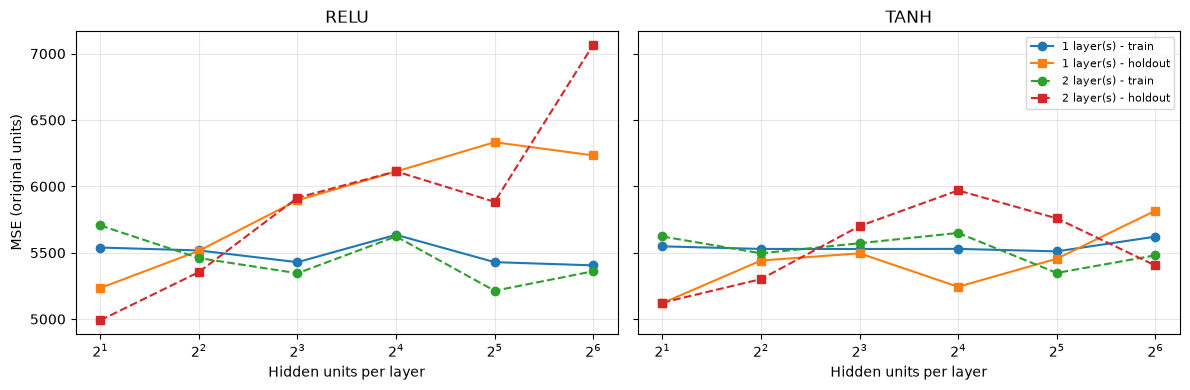

In [34]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, act in zip(axes, ["relu", "tanh"]):
    for n_layers, style in [(1, "-"), (2, "--")]:
        sub = results_df[(results_df.activation == act) & (results_df.hidden_layers == n_layers)]
        ax.plot(sub.hidden_units, sub.train_MSE, style, marker="o", label=f"{n_layers} layer(s) - train")
        ax.plot(sub.hidden_units, sub.holdout_MSE, style, marker="s", label=f"{n_layers} layer(s) - holdout")
    ax.set_xscale("log", base=2)
    ax.set_title(f"{act.upper()}")
    ax.set_xlabel("Hidden units per layer")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MSE (original units)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

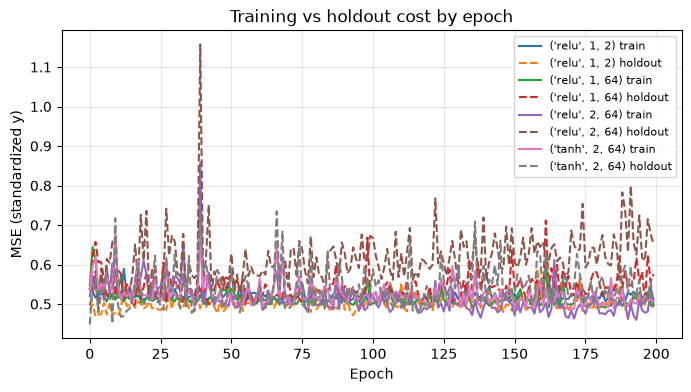

In [35]:
fig, ax = plt.subplots(figsize=(8, 4))
for key in [("relu", 1, 2), ("relu", 1, 64), ("relu", 2, 64), ("tanh", 2, 64)]:
    m = models[key]
    ax.plot(m.history["train_cost"], label=f"{key} train")
    ax.plot(m.history["val_cost"], "--", label=f"{key} holdout")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (standardized y)")
ax.set_title("Training vs holdout cost by epoch")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

**How does the number of hidden units affect performance?**

With one ReLU layer, the training MSE kept going down as we added more units (from 5,560 with 2 units to 5,369 with 64). The holdout MSE went up instead: about 5,015 to 5,090 with 2 to 4 units, and 5,563 with 64 units. The gap between holdout and training went from about -470 to +195. This is overfitting. The bigger models have more flexibility, so they start fitting the noise in the training data, and that doesn’t carry over to new data. The actual relationship in this data is linear, so a really small network (2 or 4 units) was enough, and those did the best on the holdout set.

**What changes when using two layers instead of one?**

Adding a second layer mostly just adds more capacity, kind of like adding more units. With very few units (2 or 4), two layers did about the same as one, and sometimes a little better (ReLU with 2 units: 4,973 vs 5,091). With more units, two layers overfit more. For ReLU with 64 units, holdout MSE went from 5,563 with one layer to 5,810 with two, and the gap more than doubled (+195 to +458). Extra depth helps when the data has a complicated structure. This data is linear, so the second layer mostly made the model fit more noise.

**How does the activation function (ReLU vs. Tanh) influence results?**

Tanh did a bit better than ReLU in almost every setup, and its results were more consistent. Our best model overall was Tanh with 2 layers of 4 units each (holdout MSE of 4,877, R² of 0.555). Tanh’s train/holdout gaps also stayed smaller as the models got bigger. With 2 layers and 64 units, the gap was +160 for Tanh vs +458 for ReLU. We think this is because Tanh is smooth and almost linear near zero, and since our inputs are standardized, a lot of the values fall in that range. That makes it a good fit for data that’s close to linear. ReLU builds the function out of straight pieces with sharp corners, which makes it easier to fit small bumps in the data that are really just noise. The differences were pretty small, though, so the size of the model mattered more than the activation function.

## 4. Discussion (5 points)

You created a separate class for each task and likely repeated much of the same code across implementations.

Discuss within your group how could you have leveraged inheritance to make your code more reusable and avoid duplication. Provide examples. Be specific.

Most of the code in our three classes is the same. Each class creates the weights and biases for one or two hidden layers, runs the input through those layers with ReLU or Tanh, and has a `fit` loop that does SGD (shuffle the data, compute the loss, call `backward()`, update each parameter, zero the gradients). The only real differences are the output activation (sigmoid, softmax, or none), the cost function (BCE, categorical cross-entropy, MSE), and how `predict` turns outputs into answers (threshold at 0.5, argmax, or the raw value).

With inheritance, we could put the shared parts in a parent class `BaseMLP` that handles `__init__`, the hidden-layer part of `forward`, and `fit`. Each task would then be a small subclass that only overrides what's different:


This way, a bug fix or change to the training loop (for example, tracking holdout loss every epoch) would only need to be made once instead of three times. It would also have kept our code consistent. Since each of us wrote our own class, they ended up with different argument names (`hidden_dim` vs `n_hidden`, `lr` passed to `__init__` vs to `fit`) and different ways of storing parameters. A shared parent class would have made us agree on one design from the start.

## 5. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE